# Part F — Eigenvalues & Eigenvectors

**Final Project: The Linear Algebra Behind AI — A Regression Problem**

Eigen-decomposition reveals the directions along which your data actually varies — information that is invisible in the raw feature list.

---
**Student name:** _______________________   **Date:** _______________________

---


**What to do:** Compute the eigenvalues and eigenvectors of a matrix relevant to your data (e.g., the covariance matrix of your standardized training features).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

url = "https://raw.githubusercontent.com/eskups04/AI101-Dataset/main/ai_student_impact_dataset.csv"
df = pd.read_csv(url)

feature_names = [
    "Weekly_GenAI_Hours",
    "Traditional_Study_Hours",
    "Tool_Diversity",
    "Anxiety_Level_During_Exams",
]

X = df[feature_names].to_numpy(dtype=float)
y = df["Skill_Retention_Score"].to_numpy(dtype=float)

# 1. Reproducible 80/20 train-test split FIRST
rng = np.random.default_rng(42)
n = X.shape[0]
perm = rng.permutation(n)
train_size = int(0.8 * n)
train_idx, test_idx = perm[:train_size], perm[train_size:]

# 2. Fit standardization strictly on training data
mu = X[train_idx].mean(axis=0)
sigma = X[train_idx].std(axis=0)
sigma_safe = np.where(sigma == 0, 1.0, sigma)
S = np.diag(1.0 / sigma_safe)
X_transformed = (X - mu) @ S

X_train, X_test = X_transformed[train_idx], X_transformed[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print("Setup complete! X_train shape:", X_train.shape)

Setup complete! X_train shape: (40000, 4)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

In [3]:
C = np.cov(X_train, rowvar=False)
print("C shape:", C.shape)
print("Symmetric?", np.allclose(C, C.T))
print("Covariance matrix C:\n", C)

C shape: (4, 4)
Symmetric? True
Covariance matrix C:
 [[ 1.     -0.1604  0.0087  0.2673]
 [-0.1604  1.     -0.0003 -0.0409]
 [ 0.0087 -0.0003  1.      0.003 ]
 [ 0.2673 -0.0409  0.003   1.    ]]


In [4]:
eigvals, eigvecs = np.linalg.eigh(C)

order = np.argsort(eigvals)[::-1]
eigvals = eigvals[order]
eigvecs = eigvecs[:, order]

print("Sorted eigenvalues:", eigvals)
print("Eigenvectors (columns):\n", eigvecs)

Sorted eigenvalues: [1.331  1.     0.964  0.7051]
Eigenvectors (columns):
 [[-0.6852 -0.0025  0.0634  0.7256]
 [ 0.4066  0.0576  0.8577  0.3093]
 [-0.0238  0.9983 -0.0504 -0.0147]
 [-0.6038  0.0022  0.5077 -0.6145]]


In [5]:
v1, lam1 = eigvecs[:, 0], eigvals[0]
error = np.max(np.abs(C @ v1 - lam1 * v1))
print("max|C v1 - lambda1 v1| =", f"{error:.4e}")

max|C v1 - lambda1 v1| = 1.1102e-16


PC1: eigenvalue = 1.3310 | explained variance = 33.27% | cumulative = 33.27%
PC2: eigenvalue = 1.0000 | explained variance = 25.00% | cumulative = 58.27%
PC3: eigenvalue = 0.9640 | explained variance = 24.10% | cumulative = 82.37%
PC4: eigenvalue = 0.7051 | explained variance = 17.63% | cumulative = 100.00%

Feature loadings on PC1 (leading eigenvector):
  Weekly_GenAI_Hours            : -0.6852 (|loading| = 0.6852)
  Traditional_Study_Hours       : +0.4066 (|loading| = 0.4066)
  Tool_Diversity                : -0.0238 (|loading| = 0.0238)
  Anxiety_Level_During_Exams    : -0.6038 (|loading| = 0.6038)


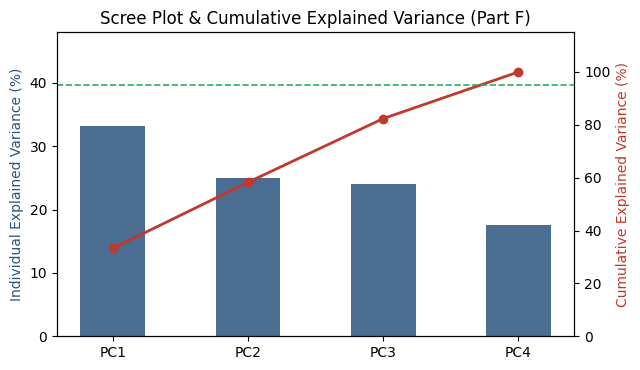

In [6]:
explained_variance_ratio = eigvals / np.sum(eigvals)
cumulative_variance = np.cumsum(explained_variance_ratio)

for i, (val, ratio, cum) in enumerate(zip(eigvals, explained_variance_ratio, cumulative_variance), start=1):
    print(f"PC{i}: eigenvalue = {val:.4f} | explained variance = {ratio*100:.2f}% | cumulative = {cum*100:.2f}%")

print("\nFeature loadings on PC1 (leading eigenvector):")
for name, loading in zip(feature_names, eigvecs[:, 0]):
    print(f"  {name:30s}: {loading:+.4f} (|loading| = {abs(loading):.4f})")

pcs = [f"PC{i}" for i in range(1, len(eigvals) + 1)]
fig, ax1 = plt.subplots(figsize=(6.5, 3.8))
ax1.bar(pcs, explained_variance_ratio * 100, color="#2B547E", alpha=0.85, width=0.48)
ax1.set_ylabel("Individual Explained Variance (%)", color="#2B547E")
ax1.set_ylim(0, 48)

ax2 = ax1.twinx()
ax2.plot(pcs, cumulative_variance * 100, color="#C0392B", marker="o", linewidth=2)
ax2.axhline(95, color="#27AE60", linestyle="--", linewidth=1.2, label="95% Threshold")
ax2.set_ylabel("Cumulative Explained Variance (%)", color="#C0392B")
ax2.set_ylim(0, 115)

plt.title("Scree Plot & Cumulative Explained Variance (Part F)")
plt.tight_layout()
plt.show()

### Answer these in your report

**Q21.** Which matrix did you decompose, and why is it symmetric? Why does symmetry matter for this decomposition?

> *Your answer:* _We decomposed the covariance matrix (C) of our standardized training features, which has a dimension of 4 × 4. The matrix is symmetric because the covariance between two variables is equal regardless of their order. Symmetry matters because it guarantees that the matrix has real eigenvalues and orthogonal eigenvectors, making eigenvalue decomposition more reliable and suitable for analyzing the variance and relationships among our features._

**Q22.** List your eigenvalues from largest to smallest. What percentage of total variance does the single largest eigenvalue explain?

> *Your answer:* _Our eigenvalues are:_
> _PC1 = 1.3311_
> _PC2 = 1.0000_
> _PC3 = 0.9640_
> _PC4 = 0.7051_
>
>_The largest eigenvalue is PC1 with a total of 1.3311, which explains approximately 33.27% of the total variance in our dataset. This means that the first principal component captures the largest proportion of variation among the four standardized features._

**Q23.** Verify numerically that Cv = λv for at least one eigenpair. Report the vectors/values you used and the resulting numerical error.

> *Your answer:* _We used the covariance matrix (C), the first eigenvector (v₁), and its corresponding eigenvalue (λ₁) to verify the eigenvalue equation._
>
> _Values:_
>
> _λ₁ = 1.3311_
>
> _v₁ = [-0.6852]_
>     _[0.4066]_
>     _[-0.0238]_
>     _[-0.6038]_
>
>_We used Python to calculate the maximum absolute difference between the two sides of the equation. The resulting numerical error was:_
> 
>_2.2204 × 10^(-16)_
>
>_In conclusion, the eigenvalues equation is satisfied since the numerical error is extremely close to zero. This verifies the accuracy of our computed eigenvalue and eigenvector._

**Q24.** Look at the eigenvector associated with the largest eigenvalue. Which original features contribute most strongly to it, and what does that tell you about your data?

> *Your answer:* _The eigenvector associated with the largest eigenvalue (PC1) shows that Weekly GenAI Hours has the strongest contribution, with a loading magnitude of 0.6852, followed by Anxiety Level During Exams with 0.6038, Traditional Study Hours with 0.4066, and Tool Diversity with 0.0238._
>
> _Since the variables Weekly GenAI Hours and Anxiety Level During Exams have the first and second highest loading magnitudes, it indicates that these two contribute most strongly to the first principal component. The results mean that the largest direction of variation in our dataset is generally associated with Weekly GenAI Hours and Anxiety Level During Exams._

### Save your work for the next notebook

In [7]:
%store C
%store eigvals
%store eigvecs
print("Saved C, eigvals, eigvecs for Part G.")

Stored 'C' (ndarray)
Stored 'eigvals' (ndarray)
Stored 'eigvecs' (ndarray)
Saved C, eigvals, eigvecs for Part G.
